# Supervised prediction with HEBI

MERFISH mouse brain, predicting annotated labels from the pretrained
representation.

The pretrained backbone produces a cell-level representation; a single
linear head maps that representation to a label. Training runs in two
phases. **Linear probing** keeps the backbone frozen and trains only the
head, which measures what the pretrained representation already contains.
**Fine-tuning** then unfreezes the backbone at a much lower learning rate,
letting the representation adapt to this dataset and this label set.

The head reads `z0`, the cell-level embedding of the seed nodes, so a
prediction is made for a cell in the context of its spatial neighbourhood.

## 1. Setup

In [8]:
import os
import json
import numpy as np
import torch

# --- edit these -------------------------------------------------------
#FOUNDATION_CKPT = "/DATA1/Roxana/Hierarchy/Two_levels/hebi_foundation_best_new.pt"
FOUNDATION_CKPT="/DATA1/Roxana/hebi_repo/notebooks/hebi_hybrid_oldL0.pt"
DATA_ROOT       = "/DATA1/Roxana/Hierarchy/Two_levels/fine_tune"
OUTPUT_DIR      = "./results/merfish_mouse_brain_2"
H5AD_PATH       = "/DATA1/Roxana/Hierarchy/data/Merfish_hebi.h5ad"
VOCAB_PATH      = "/DATA1/Roxana/Hierarchy/Two_levels/default_gene_vocab.json"
# ----------------------------------------------------------------------

TARGET_KEY  = "y_niche"      # or "y_class" for cell-type labels
DEVICE      = "cuda:0"
BATCH_SIZE  = 512
NUM_WORKERS = 4
SEED        = 42

os.makedirs(OUTPUT_DIR, exist_ok=True)
device = torch.device(DEVICE if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda:0


## 2. Building the supervised sections

Each section becomes one `.pt` file holding the expression matrix on the
shared gene vocabulary, the spatial graph, the METIS partition, the gene
ids, and both label vectors. Sections go into `train/` or `test/` according
to the `split` column already present in `obs`, and the name-to-integer
mappings are written once as `label_mappings.json` so that every section
encodes labels the same way.

Run this once. It skips any section whose `.pt` already exists, so changing
`k` or the label columns means deleting the old files first.

In [2]:
from pathlib import Path
import scanpy as sc
from tqdm import tqdm

from hebi.data.graph import build_spatial_graph
from hebi.data.coarsening import create_metis_partition
from hebi.data.vocabulary import harmonise_adata

BUILD_SECTIONS = False       # set True the first time

LABEL_COL_CLASS = "class"
LABEL_COL_NICHE = "niche"
SECTION_COL     = "brain_section_label"
SPLIT_COL       = "split"
K_NEIGHBORS     = 10

if BUILD_SECTIONS:
    root = Path(DATA_ROOT)
    (root / "train").mkdir(parents=True, exist_ok=True)
    (root / "test").mkdir(parents=True, exist_ok=True)

    adata_full = sc.read_h5ad(H5AD_PATH)
    sc.pp.log1p(adata_full)

    class_to_id = {l: i for i, l in
                   enumerate(sorted(adata_full.obs[LABEL_COL_CLASS].unique().astype(str)))}
    niche_to_id = {l: i for i, l in
                   enumerate(sorted(adata_full.obs[LABEL_COL_NICHE].unique().astype(str)))}

    with open(root / "label_mappings.json", "w") as f:
        json.dump({"class_mapping": class_to_id, "niche_mapping": niche_to_id},
                  f, indent=4)
    print(f"{len(class_to_id)} classes, {len(niche_to_id)} niches")

    for section_id in tqdm(adata_full.obs[SECTION_COL].unique()):
        ad = adata_full[adata_full.obs[SECTION_COL] == section_id].copy()
        split = ad.obs[SPLIT_COL].iloc[0]
        out_file = root / ("test" if split == "test" else "train") / f"{section_id}.pt"
        if out_file.exists():
            continue

        ad = harmonise_adata(ad, VOCAB_PATH, fine_tune=True, species="Mouse")

        X = ad.X.toarray() if hasattr(ad.X, "toarray") else np.asarray(ad.X)
        X = torch.tensor(X, dtype=torch.float32)
        coords = torch.tensor(
            ad.obsm["spatial"] if "spatial" in ad.obsm else ad.obsm["spatial_3d"][:, :2],
            dtype=torch.float32,
        )

        edge_index, edge_attr, _ = build_spatial_graph(coords.numpy(), k=K_NEIGHBORS)

        # METIS needs fewer communities than cells on small sections.
        n_clusters = 1024 if ad.n_obs >= 1024 else max(1, ad.n_obs // 10)
        node2comm, super_sp = create_metis_partition(
            edge_index, X.shape[0], n_clusters, seed=SEED
        )

        torch.save({
            "X": X.half(),
            "coords": coords,
            "edge_index": edge_index,
            "node2comm": node2comm,
            "super_sp": super_sp,
            "gene_ids": torch.tensor(ad.var["gene_id"].values, dtype=torch.long),
            "y_class": torch.tensor(
                [class_to_id[l] for l in ad.obs[LABEL_COL_CLASS].astype(str)],
                dtype=torch.long),
            "y_niche": torch.tensor(
                [niche_to_id[l] for l in ad.obs[LABEL_COL_NICHE].astype(str)],
                dtype=torch.long),
            "meta": {"species": "Mouse", "tissue": "Brain", "disease": "Normal",
                     "k_neighbors": K_NEIGHBORS},
        }, out_file)

    del adata_full

/home/tower4/miniconda3/envs/hebi/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 3. Labels

`label_mappings.json` sits next to the `.pt` sections and holds the
name-to-integer mapping used when the supervised sections were built. It is
the single source of truth for how many classes there are and what each
integer means, so nothing downstream hardcodes a class count.

`y_class` and `y_niche` have separate mappings. Reading the wrong one gives
a model with the wrong number of output units, which trains without error
and produces meaningless labels.

In [3]:
with open(os.path.join(DATA_ROOT, "label_mappings.json")) as f:
    mappings = json.load(f)

mapping_key = "class_mapping" if TARGET_KEY == "y_class" else "niche_mapping"
label_to_id = mappings[mapping_key]
id_to_label = {v: k for k, v in label_to_id.items()}
label_names = [id_to_label[i] for i in range(len(id_to_label))]
n_classes   = len(label_names)

print(f"{TARGET_KEY}: {n_classes} classes")
for i, name in enumerate(label_names):
    print(f"  {i:>2}  {name}")

y_niche: 7 classes
   0  CBX-MOB-other neuronal
   1  Immune
   2  Neuroglial
   3  PAL-sAMY-TH-HY-MB-HB neuronal
   4  Pallium glutamatergic
   5  Subpallium GABAergic
   6  Vascular


In [5]:
import scanpy as sc
import pandas as pd

H5AD_PATH = "/DATA1/Roxana/Hierarchy/data/Merfish_hebi.h5ad"
adata = sc.read_h5ad(H5AD_PATH)
print(adata)

ct = pd.crosstab(adata.obs["class"], adata.obs["niche"])
n_niche_per_class = (ct > 0).sum(axis=1)
print(n_niche_per_class.value_counts())

AnnData object with n_obs × n_vars = 3938808 × 479
    obs: 'brain_section_label', 'class', 'subclass', 'supertype', 'cluster', 'cluster_alias', 'neurotransmitter', 'niche', 'class_label', 'class_clean', 'region', 'division_id', 'region_seed', 'clean_region_label', 'is_test_section', 'split'
    var: 'gene_symbol', 'transcript_identifier', 'Human gene stable ID', 'orthologous_gene_id'
    uns: 'accessed_on', 'brain_section_label_colors', 'class_colors', 'cluster_alias_colors', 'cluster_colors', 'neurotransmitter_colors', 'niche_colors', 'src', 'subclass_colors', 'supertype_colors', 'test_set_section_ids'
    obsm: 'spatial', 'spatial_3d'
1    34
Name: count, dtype: int64


## 4. Training

`train_classifier` runs both phases and writes checkpoints and a training
history into `OUTPUT_DIR`.

Two things worth knowing about how it selects.

**Selection is on macro-F1, not accuracy.** Macro-F1 averages the per-class
F1 without weighting by class size, so a rare label counts as much as a
common one. Where the label distribution is uneven, accuracy is dominated
by the largest class and a model that predicts only that class can still
look good.

**The two phases use different learning rates.** The head trains at
`lr_linear` throughout; in phase two the backbone moves at `lr_finetune`,
typically two orders of magnitude smaller. A large learning rate on the
backbone erases what pretraining learned within a few steps.

Prototype counts are read from the checkpoint, so a 256-prototype
checkpoint loads as readily as a 1024-prototype one.

In [9]:
from hebi.training.finetune.train_classifier import train_classifier

history = train_classifier(
    foundation_ckpt=FOUNDATION_CKPT,
    data_root=DATA_ROOT,
    output_dir=OUTPUT_DIR,
    target_key=TARGET_KEY,
    level="cell",
    n_epochs_linear=5,
    lr_linear=1e-3,

    do_finetune=False,
    n_epochs_finetune=5,
    lr_finetune=1e-5,

    batch_size=BATCH_SIZE,
    device=DEVICE,
    num_workers=NUM_WORKERS,
    seed=SEED,
)

Task: y_niche (7 classes) | level: cell | niche prototypes: 20
📥 Loading checkpoint: /DATA1/Roxana/hebi_repo/notebooks/hebi_hybrid_oldL0.pt
❄️ Backbone frozen
📁 Found 54 slides for split 'train'
📁 Found 5 slides for split 'test'

Phase 1: linear probing (5 epochs)


P1 1/5: 100%|████████████| 54/54 [02:51<00:00,  3.18s/it, acc=0.952, loss=0.143]


  P1 ep 1 | train acc=0.9525  macroF1=0.9415  microF1=0.9525
           | test  acc=0.9390  macroF1=0.9093  microF1=0.9390
           | saved (macroF1 0.9093)


P1 2/5: 100%|████████████| 54/54 [02:48<00:00,  3.12s/it, acc=0.964, loss=0.101]


  P1 ep 2 | train acc=0.9637  macroF1=0.9567  microF1=0.9637
           | test  acc=0.9510  macroF1=0.9337  microF1=0.9510
           | saved (macroF1 0.9337)


P1 3/5: 100%|██████████████| 54/54 [02:38<00:00,  2.93s/it, acc=0.964, loss=0.1]


  P1 ep 3 | train acc=0.9642  macroF1=0.9572  microF1=0.9642
           | test  acc=0.9387  macroF1=0.9205  microF1=0.9387


P1 4/5: 100%|████████████| 54/54 [02:37<00:00,  2.91s/it, acc=0.963, loss=0.102]


  P1 ep 4 | train acc=0.9634  macroF1=0.9565  microF1=0.9634
           | test  acc=0.9231  macroF1=0.8806  microF1=0.9231


P1 5/5: 100%|████████████| 54/54 [02:39<00:00,  2.96s/it, acc=0.964, loss=0.101]


  P1 ep 5 | train acc=0.9641  macroF1=0.9573  microF1=0.9641
           | test  acc=0.9616  macroF1=0.9469  microF1=0.9616
           | saved (macroF1 0.9469)

Skipping phase 2.

Best macro-F1: 0.9469
Outputs in ./results/merfish_mouse_brain_2


Plotting both phases on one axis shows what fine-tuning actually bought.
If the curve is flat after the phase boundary, the frozen representation was
already sufficient and the extra compute bought nothing. If train macro-F1
climbs while test macro-F1 falls, the backbone is fitting the training
sections.

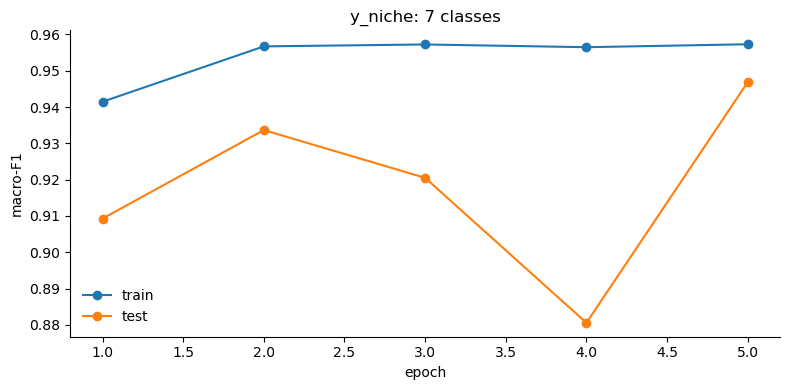

best test macro-F1 0.9469 (phase 1, epoch 5), accuracy 0.9616


In [10]:
import matplotlib.pyplot as plt

train_f1 = [h["train"]["macro_f1"] for h in history]
test_f1  = [h["test"]["macro_f1"] for h in history]
phase    = [h["phase"] for h in history]
x        = np.arange(1, len(history) + 1)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x, train_f1, "o-", label="train")
ax.plot(x, test_f1,  "o-", label="test")

if 2 in phase:
    boundary = phase.index(2) + 0.5
    ax.axvline(boundary, color="grey", ls="--", lw=1)
    ax.text(boundary + 0.1, min(test_f1), " fine-tuning", fontsize=9,
            color="grey", va="bottom")

ax.set_xlabel("epoch")
ax.set_ylabel("macro-F1")
ax.set_title(f"{TARGET_KEY}: {n_classes} classes")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

best = max(history, key=lambda h: h["test"]["macro_f1"])
print(f"best test macro-F1 {best['test']['macro_f1']:.4f} "
      f"(phase {best['phase']}, epoch {best['epoch']}), "
      f"accuracy {best['test']['accuracy']:.4f}")

## 5. Predicting whole sections

For the confusion matrix and the spatial maps, each prediction has to be
matched to the cell that produced it.

`iterate_supervised_batches` yields labels but not the seed node indices, so
predictions come back in sampler order with no way to recover which cell each
one belongs to. The function below repeats the same unpacking and keeps the
indices, writing each prediction into an array in the section's own cell
order. Nothing in the package changes.

In [12]:
from hebi.training.finetune.finetuner import HebiClassifier
from hebi.training.finetune.loader import (
    get_slide_list, load_supervised_slide_dict, build_local_sampler,
)


def load_trained_model(checkpoint_path, n_classes, foundation_ckpt, device,level="cell"):
    ckpt = torch.load(foundation_ckpt, map_location="cpu")
    k2 = ckpt["pooler_lvl2"]["l2_prototypes"].shape[0]
    del ckpt

    model = HebiClassifier(n_classes=n_classes, level=level,
                           num_prototypes_lvl2=k2).to(device)
    model.load_pretrained_weights(foundation_ckpt, device, freeze_backbone=False)
    model.load_state_dict(torch.load(checkpoint_path, map_location=device))
    model.eval()
    return model


@torch.no_grad()
def predict_section(model, pt_path, target_key, device,
                    batch_size=512, num_workers=4):
    """Predict every cell in one section, in the section's own cell order.

    Returns (pred, true), both length n_cells. Cells that never appear as a
    seed node keep -1 and are reported.
    """
    slide   = load_supervised_slide_dict(pt_path, target_key=target_key)
    sampler = build_local_sampler(slide, batch_size=batch_size,
                                  shuffle=False, num_workers=num_workers)

    X         = slide["X"].float().to(device)
    node2comm = slide["node2comm"].long().to(device)
    super_sp  = slide["super_sp"].float().to(device)
    gene_ids  = slide["gene_ids"].long().to(device)
    true      = slide[target_key].long().cpu().numpy()

    # niche level: whole-section community representations, as in evaluate()
    global_reps = None
    if model.level == "niche":
        global_reps = model.section_global_reps(
            slide, device, batch_size=batch_size, num_workers=num_workers)

    pred = np.full(X.shape[0], -1, dtype=np.int64)

    for edge_block, node_idx_b, bs in sampler:
        node_idx_b = node_idx_b.to(device)
        seed = node_idx_b[:bs]
        logits = model(
            x_subgraph_raw=X[node_idx_b],
            edge_index_subgraph=edge_block[:2].to(device),
            edge_attr_b=(edge_block[2].to(device), edge_block[3].to(device)),
            node2comm_batch=node2comm[seed],
            super_sp_global=super_sp,
            gene_ids=gene_ids,
            device=device,
            bs=bs,
            global_reps=global_reps,
        )
        pred[seed.cpu().numpy()] = logits.argmax(dim=1).cpu().numpy()

    unseen = int((pred < 0).sum())
    if unseen:
        print(f"  {unseen} cells never appeared as a seed node")
    return pred, true

In [13]:
LEVEL = "cell"          # MERFISH; for liver: "niche"

CHECKPOINT = os.path.join(OUTPUT_DIR, "best_finetuned_model.pt")
if not os.path.exists(CHECKPOINT):
    CHECKPOINT = os.path.join(OUTPUT_DIR, "best_probe_model.pt")
print("using", CHECKPOINT)

model = load_trained_model(CHECKPOINT, n_classes, FOUNDATION_CKPT, device,
                           level=LEVEL)
test_files = get_slide_list(DATA_ROOT, split="test")

per_section = {}
for pt_path in test_files:
    name = os.path.basename(pt_path).replace(".pt", "")
    pred, true = predict_section(model, pt_path, TARGET_KEY, device,
                                 batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)
    per_section[name] = {"pred": pred, "true": true}
    acc = float((pred == true)[pred >= 0].mean())
    print(f"{name:<40} {len(pred):>7,} cells   acc {acc:.4f}")

using ./results/merfish_mouse_brain_2/best_probe_model.pt
📥 Loading checkpoint: /DATA1/Roxana/hebi_repo/notebooks/hebi_hybrid_oldL0.pt
🔥 Backbone trainable
📁 Found 5 slides for split 'test'
C57BL6J-638850.12                         50,612 cells   acc 0.9413
C57BL6J-638850.31                         91,988 cells   acc 0.9673
C57BL6J-638850.33                         85,849 cells   acc 0.9710
C57BL6J-638850.42                         75,551 cells   acc 0.9560
C57BL6J-638850.50                         92,826 cells   acc 0.9629


## 6. Confusion matrix

The matrix is computed on integer class ids, not names. Passing the label
names to `labels=` while the predictions are integers produces an all-zero
matrix without raising anything, so the names are used only for the tick
labels.

Rows are normalised, so each row shows how the cells of one true class were
distributed across predictions. The diagonal is per-class recall.
Off-diagonal mass is the useful part: confusion between labels that are
genuinely adjacent in the tissue is a different failure from confusion
between unrelated ones.

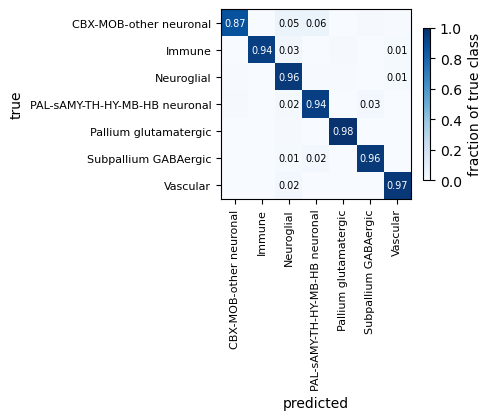

                               precision    recall  f1-score   support

       CBX-MOB-other neuronal       0.93      0.87      0.90     17858
                       Immune       0.92      0.94      0.93      5721
                   Neuroglial       0.96      0.96      0.96    124801
PAL-sAMY-TH-HY-MB-HB neuronal       0.92      0.94      0.93     41838
        Pallium glutamatergic       0.99      0.98      0.99    104654
         Subpallium GABAergic       0.97      0.96      0.96     56882
                     Vascular       0.95      0.97      0.96     45072

                     accuracy                           0.96    396826
                    macro avg       0.95      0.95      0.95    396826
                 weighted avg       0.96      0.96      0.96    396826



In [14]:
from sklearn.metrics import confusion_matrix, classification_report

y_true = np.concatenate([d["true"][d["pred"] >= 0] for d in per_section.values()])
y_pred = np.concatenate([d["pred"][d["pred"] >= 0] for d in per_section.values()])

cm = confusion_matrix(y_true, y_pred, labels=np.arange(n_classes))
cm_norm = cm / (cm.sum(axis=1, keepdims=True) + 1e-12)

fig, ax = plt.subplots(figsize=(1 + 0.55 * n_classes, 0.9 + 0.5 * n_classes))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
fig.colorbar(im, ax=ax, shrink=0.7, label="fraction of true class")

ax.set_xticks(np.arange(n_classes))
ax.set_yticks(np.arange(n_classes))
ax.set_xticklabels(label_names, rotation=90, fontsize=8)
ax.set_yticklabels(label_names, fontsize=8)
ax.set_xlabel("predicted")
ax.set_ylabel("true")

for i in range(n_classes):
    for j in range(n_classes):
        if cm_norm[i, j] > 0.01:
            ax.text(j, i, f"{cm_norm[i, j]:.2f}", ha="center", va="center",
                    fontsize=7, color="white" if cm_norm[i, j] > 0.5 else "black")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "confusion_matrix.svg"))
plt.show()

print(classification_report(y_true, y_pred, labels=np.arange(n_classes),
                            target_names=label_names, zero_division=0))

## 7. Predictions in space

Aggregate metrics say how often the model is right, not where it is wrong.
Plotting predicted against annotated labels on the same section shows
whether the errors are scattered or concentrated, and concentrated errors
along a boundary mean something different from scattered ones.

The `.pt` section fixes the cell order, so the AnnData being plotted must
hold the same cells in the same order. The cell below checks the count and
stops if it disagrees rather than silently plotting a shifted assignment.

/tmp/ipykernel_1467217/3888221983.py:26: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(sub, color=["annotated", "predicted"], spot_size=SPOT_SIZE,


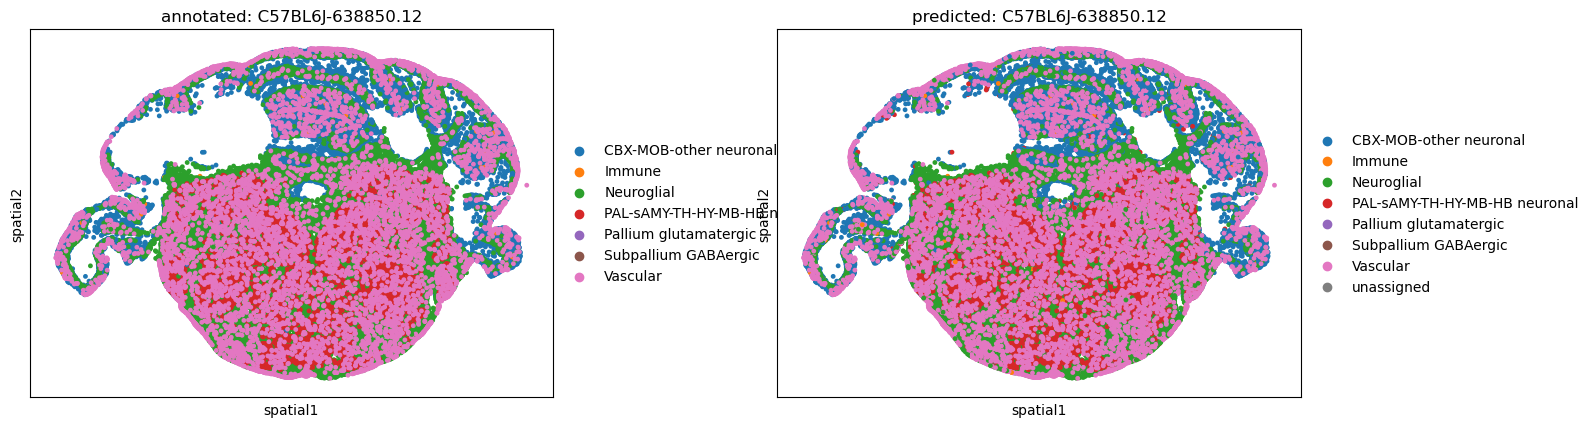

In [15]:
import scanpy as sc
import pandas as pd

SECTION = list(per_section)[0]        # which test section to plot
SECTION_KEY = SECTION_COL             # obs column identifying sections
SPOT_SIZE = 0.09

adata = sc.read_h5ad(H5AD_PATH)
sub = adata[adata.obs[SECTION_KEY].astype(str) == SECTION].copy()

pred = per_section[SECTION]["pred"]
assert sub.n_obs == len(pred), (
    f"{sub.n_obs} cells in the AnnData but {len(pred)} in the section file. "
    "The .pt fixes the cell order, so these must match."
)

sub.obs["predicted"] = pd.Categorical(
    [label_names[i] if i >= 0 else "unassigned" for i in pred],
    categories=label_names + ["unassigned"],
)
sub.obs["annotated"] = pd.Categorical(
    [label_names[i] for i in per_section[SECTION]["true"]],
    categories=label_names,
)

sc.pl.spatial(sub, color=["annotated", "predicted"], spot_size=SPOT_SIZE,
              title=[f"annotated: {SECTION}", f"predicted: {SECTION}"],
              wspace=0.3, show=True)

2,971 of 50,612 cells misclassified (5.9%)


/tmp/ipykernel_1467217/460682740.py:8: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(sub, color="error", spot_size=SPOT_SIZE,


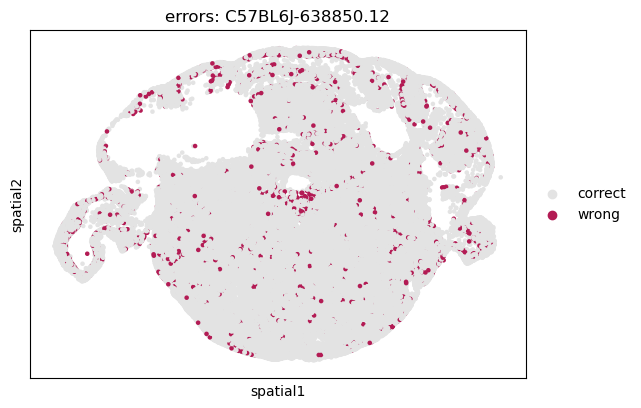

In [16]:
mismatch = (sub.obs["annotated"].astype(str) != sub.obs["predicted"].astype(str))
sub.obs["error"] = pd.Categorical(
    np.where(mismatch, "wrong", "correct"), categories=["correct", "wrong"]
)
print(f"{mismatch.sum():,} of {sub.n_obs:,} cells misclassified "
      f"({mismatch.mean():.1%})")

sc.pl.spatial(sub, color="error", spot_size=SPOT_SIZE,
              palette=["#E3E3E3", "#B31B54"],
              title=f"errors: {SECTION}", show=True)

Where the two panels differ is worth reading directly. Errors along the
boundary between two labels are a resolution limit: the model places the
transition a cell or two off. Errors scattered through the interior of a
region are a different problem, and usually mean the label is not separable
from its neighbours in this representation, which the corresponding row of
the confusion matrix will already have shown.